### Challenge 1: Predict the Output

---
- **Circuit A:** One Pauli-$X$ gate followed by measurement.
- **Circuit B:** Two consecutive Pauli-$X$ gates followed by measurement.
- **Circuit C:** One Hadamard ($H$) gate followed by measurement.



In [7]:
# Step 1: Import required Qiskit and visualization modules
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

# Initialize the Aer simulator backend
simulator = AerSimulator()
print("AerSimulator initialized successfully.")


AerSimulator initialized successfully.


---
## Circuit A: Single Pauli-$X$ Gate

### Prediction Before Execution
- **State before measurement:** $|1>$
- **Theoretical probability of obtaining 0:** $P(0) = |\langle 0 | 1 \rangle|^2 = 0.0$ ($0\%$)
- **Theoretical probability of obtaining 1:** $P(1) = |\langle 1 | 1 \rangle|^2 = 1.0$ ($100\%$)
- **Predicted outcome for 100 shots:** Deterministically **100 counts for '1'** and **0 counts for '0'**.


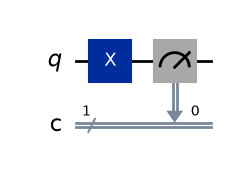

Circuit A Measurement Results (100 shots): {'1': 100}


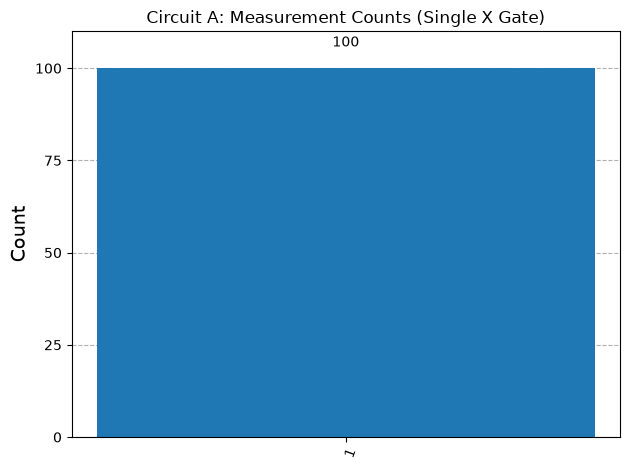

In [12]:
# Initialize 1 qubit and 1 classical bit
qc_a = QuantumCircuit(1, 1, name="Circuit A (Single X)")

# Apply one X gate
qc_a.x(0)

# Measure the qubit into the classical bit
qc_a.measure(0, 0)

# Display readable circuit diagram
display(qc_a.draw("mpl"))

# Execute for exactly 100 shots
shots = 100
job_a = simulator.run(qc_a, shots=shots)
result_a = job_a.result()
counts_a = result_a.get_counts()

print("Circuit A Measurement Results (100 shots):", counts_a)
plot_histogram(counts_a, title="Circuit A: Measurement Counts (Single X Gate)")


---
## Circuit B: Two Consecutive Pauli-$X$ Gates

### Prediction Before Execution
- **State before measurement:** $|0>$
- **Theoretical probability of obtaining 0:** $P(0) = |\langle 0 | 0 \rangle|^2 = 1.0$ ($100\%$)
- **Theoretical probability of obtaining 1:** $P(1) = |\langle 1 | 0 \rangle|^2 = 0.0$ ($0\%$)
- **Predicted outcome for 100 shots:** Deterministically **100 counts for '0'** and **0 counts for '1'**.


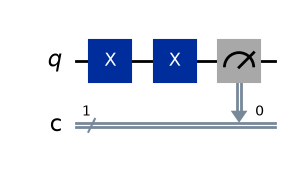

Circuit B Measurement Results (100 shots): {'0': 100}


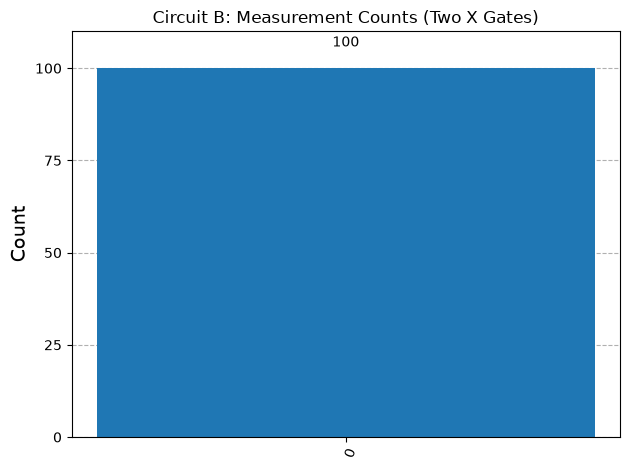

In [13]:
qc_b = QuantumCircuit(1, 1, name="Circuit B (Two X Gates)")

# Apply two consecutive X gates
qc_b.x(0)
qc_b.x(0)

# Measure qubit 0 into classical bit 0
qc_b.measure(0, 0)

# Display readable circuit diagram
display(qc_b.draw("mpl"))

# Execute for exactly 100 shots
job_b = simulator.run(qc_b, shots=shots)
result_b = job_b.result()
counts_b = result_b.get_counts()

print("Circuit B Measurement Results (100 shots):", counts_b)
plot_histogram(counts_b, title="Circuit B: Measurement Counts (Two X Gates)")


---
## Circuit C: Hadamard Gate (Equal Superposition)

### Prediction Before Execution
- **State before measurement:** Equal superposition $|+\rangle = \frac{1}{\sqrt{2}}(|0\rangle + |1\rangle)$
- **Expected probability distribution:** $50\% \text{ '0'}, \quad 50\% \text{ '1'}$
- **Expected counts for 100 shots:** Approximately **50 counts for '0'** and **50 counts for '1'**.


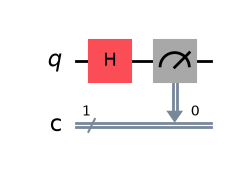

Circuit C Measurement Results (100 shots): {'0': 44, '1': 56}


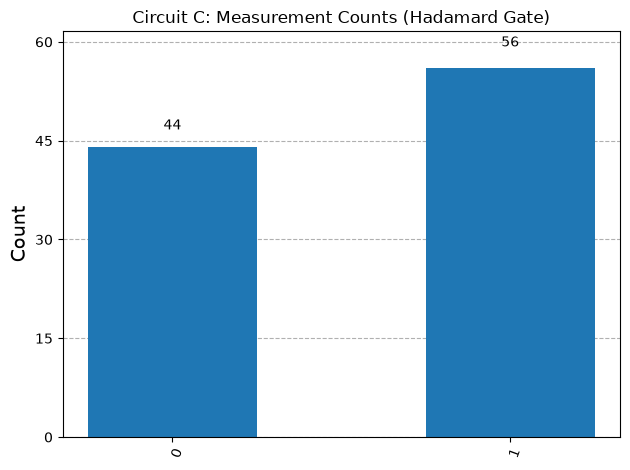

In [14]:
qc_c = QuantumCircuit(1, 1, name="Circuit C (Hadamard Gate)")

# Apply Hadamard gate
qc_c.h(0)

# Measure qubit 0 into classical bit 0
qc_c.measure(0, 0)

# Display readable circuit diagram
display(qc_c.draw("mpl"))

# Execute for exactly 100 shots
job_c = simulator.run(qc_c, shots=shots)
result_c = job_c.result()
counts_c = result_c.get_counts()

print("Circuit C Measurement Results (100 shots):", counts_c)
plot_histogram(counts_c, title="Circuit C: Measurement Counts (Hadamard Gate)")


## Comparative Visualization of All Three Circuits

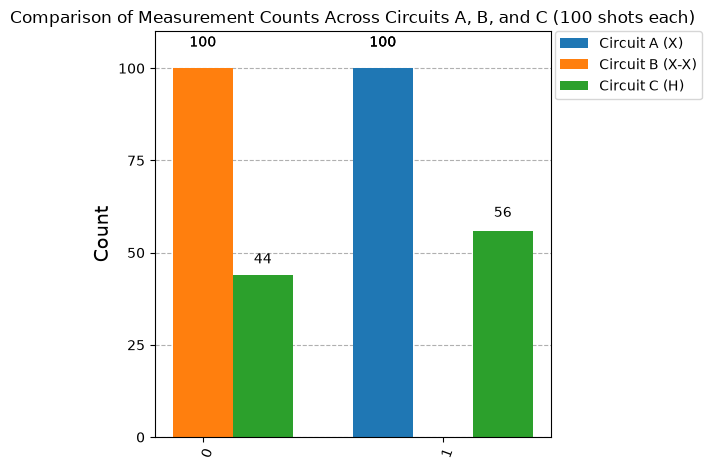

In [15]:
plot_histogram(
    [counts_a, counts_b, counts_c],
    legend=["Circuit A (X)", "Circuit B (X-X)", "Circuit C (H)"],
    title="Comparison of Measurement Counts Across Circuits A, B, and C (100 shots each)"
)


---
## Comparison Between Predicted and Observed Results

| Circuit | Applied Gates | Prepared State | Predicted $P(0)$ | Predicted $P(1)$ | Expected Counts (100 shots) | Observed Counts | Agreement |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| **Circuit A** | $X$ | $|1\rangle$ | $0.0\%$ | $100.0\%$ | 0 '0', 100 '1' | `1: 100` | Exact (Deterministic) |
| **Circuit B** | $X, X$ | $|0\rangle$ | $100.0\%$ | $0.0\%$ | 100 '0', 0 '1' | `0: 100` | Exact (Deterministic) |
| **Circuit C** | $H$ | $\frac{|0\rangle + |1\rangle}{\sqrt{2}}$ | $50.0\%$ | $50.0\%$ | ~50 '0', ~50 '1' | Close to 50/50 | Consistent (Probabilistic) |

###  Explanation
1. **Circuits A and B are deterministic:**
   The states $|1\rangle$ and $|0\rangle$ are eigenstates of the computational basis ($Z$-basis measurement operator $\sigma_z$). Because the qubit is in a pure basis state, projecting onto the measurement basis has eigenvalue probability $1.0$. Therefore, every single shot in Circuit A yields $1$, and every shot in Circuit B yields $0$.

2. **Circuit C is probabilistic:**
   The Hadamard gate rotates the state vector into the equal superposition state $|+\rangle$ along the $+X$ axis of the Bloch sphere. When measured in the computational $Z$-basis, the state vector collapses randomly into either $|0\rangle$ or $|1\rangle$ with equal probability $p = 0.5$. Because we perform a finite sample of $N=100$ independent trials, the count distribution follows a Binomial distribution $B(N=100, p=0.5)$ with standard deviation $\sigma = \sqrt{100 \times 0.5 \times 0.5} = 5.0$. Small deviations from 50 (such as 48/52 or 53/47) are expected statistical fluctuations.
